# Efek Campaign Voucher: Difference-in-Differences — Observasional

Retailer yang memilih siapa yang dikirimi campaign bukan undian acak — tidak ada angka di notebook ini yang berdiri sebagai klaim kausal. Semua estimasi berlabel **`observasional — di bawah asumsi unconfoundedness`**, dan pekerjaan utamanya adalah menguji seberapa jauh asumsi itu bertahan.

Investigasi di balik notebook ini menemukan satu hal yang mengubah desain: targeting campaign ini bercorak **win-back** — member dipilih justru saat spend-nya sedang turun, lalu sebagian pemulihannya terjadi secara alami (mean reversion). Tanpa mengkondisikan pola itu, sebagian lift yang terbaca sebenarnya pemulihan alami, bukan efek campaign. Karena itu propensity score kini memuat **trajektori spend** dan **level dip** pra-campaign, dan reliabilitas dijaga **dua placebo**: jendela pre yang berdekatan dan jendela jauh yang tidak pernah disentuh model.

Hasil akhirnya: dari 20 campaign layak, **14 lolos semua gate**. Backbone yang bersih: campaign 8 (+9,8%) dan 13 (+15,2%) — keduanya signifikan setelah koreksi multiplicity. Campaign 18 signifikan secara aritmetika (+18,1%) tapi **gagal placebo jauh** dan ditandai. Efek rata-rata lintas campaign reliable: **$3,8–$4,9 spend mingguan per member treated**.

## 0. Setup

In [1]:
import sys
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.did import build_campaign_results, pooled_effect
from src.features import PROCESSED_DIR, save_parquet

panel = pd.read_parquet(PROCESSED_DIR / "hh_week.parquet")
timeline = pd.read_parquet(PROCESSED_DIR / "campaign_timeline.parquet")
hh_campaign = pd.read_parquet(PROCESSED_DIR / "hh_campaign.parquet")
results, events = build_campaign_results(timeline, hh_campaign, panel)
save_parquet(results, PROCESSED_DIR / "campaign_did_results.parquet")
save_parquet(events, PROCESSED_DIR / "campaign_event_study.parquet")
est = results[results["estimated"]].copy()
print(f"{len(results)} campaign | {len(est)} diperkirakan | {len(events):,} baris event study")

30 campaign | 20 diperkirakan | 574 baris event study


## 1. Siapa dibandingkan dengan siapa

Treated dibandingkan dengan member yang tidak ditarget campaign itu **dan** tidak sedang menerima campaign lain yang window-nya beririsan; baseline spend dari 8 minggu sebelum campaign; efek diukur pada rata-rata spend mingguan selama window. Tujuh fitur pra-campaign masuk propensity: level spend, frekuensi aktif, ketergantungan promo, ragam kategori, recency, **trajektori spend** (paruh akhir minus paruh awal window pre), dan **level dip** (rata-rata minggu −12 s.d. −9). Dua yang terakhir inilah yang membuat kontrol menyerupai treated pada dinamikanya, bukan hanya levelnya.

In [2]:
cols = ["campaign_id", "type", "n_weeks_window", "n_treated_analysis", "n_control_analysis"]
view = est[cols].copy()
view["n_control_analysis"] = view["n_control_analysis"].astype(int)
view  # sampel penuh: overlap weights tidak mem-trim

,campaign_id,type,n_weeks_window,n_treated_analysis,n_control_analysis
4,5,B,5,166.0,2052
6,7,B,5,198.0,1384
7,8,A,7,1076.0,1359
8,9,B,5,176.0,1365
9,10,B,5,123.0,1951
10,11,B,7,214.0,1377
11,12,B,5,170.0,1377
12,13,A,7,1077.0,1374
13,14,C,10,224.0,1150
15,16,B,5,188.0,1308


## 2. Seleksi win-back, dan kenapa dua placebo

Ketika propensity hanya memuat level, placebo di jendela pre yang **jauh** dari campaign (minggu −24 s.d. −17 — jendela yang tidak pernah dipakai model) gagal untuk 15 dari 20 campaign dengan tanda negatif konsisten: treated memang sedang **menurun** relatif terhadap kontrol jauh sebelum dikirimi apa pun. Itu tanda tangan targeting win-back plus pemulihan alami — dan berarti DiD sederhana akan membaca sebagian pemulihan itu sebagai efek campaign.

Setelah trajektori dan level dip dikondisikan, placebo jauh gagal tinggal 6 dari 20 — dan keenamnya ditandai `tidak reliable — pre-trend jauh`, termasuk campaign 18. Placebo dalam jendela lolos untuk semua 20, dan balance (SMD < 0,1) tetap sempurna. Perbedaan estimasi sebelum-sesudah pengondisian (~30% lebih rendah) diungkap apa adanya: itu bagian lift yang ternyata bukan efek.

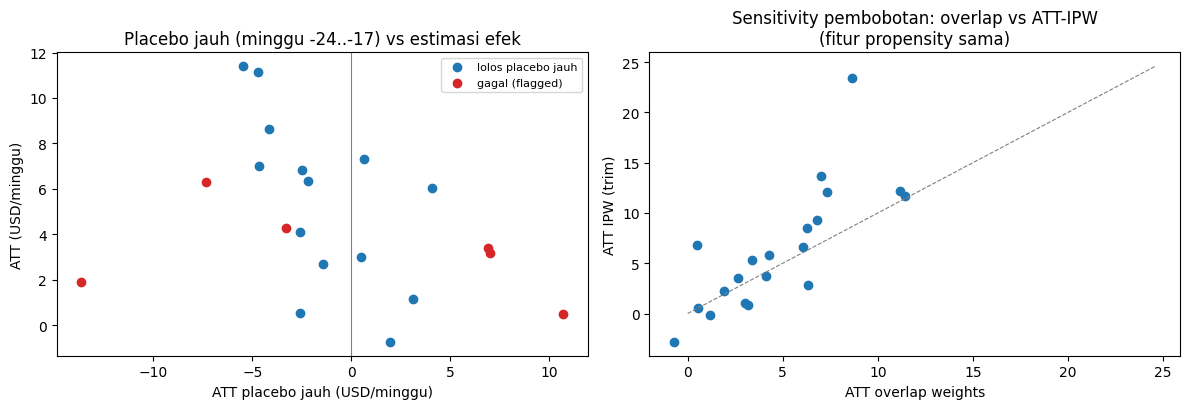

placebo jauh gagal: [7, 10, 17, 18, 25, 26] | balance lolos: 20/20


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ok = est["far_pre_trend_ok"]
axes[0].scatter(est.loc[ok, "placebo_far_att"], est.loc[ok, "att"], color="#1f77b4", label="lolos placebo jauh")
axes[0].scatter(est.loc[~ok, "placebo_far_att"], est.loc[~ok, "att"], color="#d62728", label="gagal (flagged)")
axes[0].axvline(0, color="gray", lw=0.8)
axes[0].set(title="Placebo jauh (minggu -24..-17) vs estimasi efek", xlabel="ATT placebo jauh (USD/minggu)", ylabel="ATT (USD/minggu)")
axes[0].legend(fontsize=8)
axes[1].scatter(est["att"], est["att_ipw_sensitivity"], color="#1f77b4")
lim = max(est["att"].max(), est["att_ipw_sensitivity"].max()) * 1.05
axes[1].plot([0, lim], [0, lim], color="gray", lw=0.8, ls="--")
axes[1].set(title="Sensitivity pembobotan: overlap vs ATT-IPW\n(fitur propensity sama)", xlabel="ATT overlap weights", ylabel="ATT IPW (trim)")
plt.tight_layout()
plt.show()
print(f"placebo jauh gagal: {sorted(est.loc[~ok, 'campaign_id'].tolist())} | balance lolos: {(est['smd_max_after'] < 0.1).sum()}/20")

## 3. Event study backbone

Spend mingguan berbobot treated vs kontrol di sekitar awal campaign. Campaign 8 dan 13: pre-period sejajar, berpisah setelah minggu 0 — pola yang DiD asumsikan, lolos kedua placebo. Campaign 18: dinamika pra-campaignnya tidak sepenuhnya sejajar di jendela jauh — estimasinya signifikan, tapi asumsi identifikasinya goyah, maka ditandai.

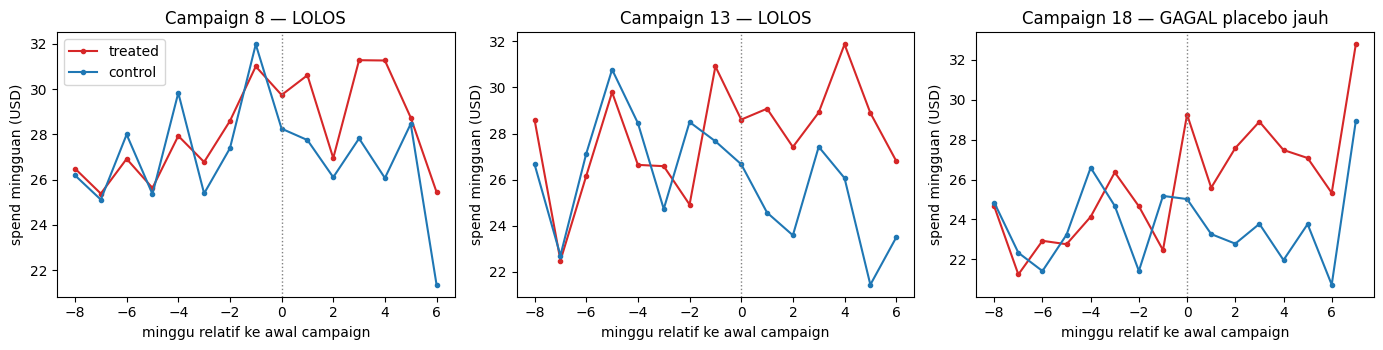

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=False)
for ax, cid in zip(axes, (8, 13, 18)):
    sub = events[events["campaign_id"] == cid]
    for grp, color in (("treated", "#d62728"), ("control", "#1f77b4")):
        g = sub[sub["group"] == grp]
        ax.plot(g["event_week"], g["mean_weekly_spend"], "-o", ms=3, color=color, label=grp)
    ax.axvline(0, color="gray", ls=":", lw=1)
    row = est[est["campaign_id"] == cid].iloc[0]
    verdict = "LOLOS" if (row["pre_trend_ok"] and row["far_pre_trend_ok"]) else "GAGAL placebo jauh"
    ax.set(title=f"Campaign {cid} — {verdict}", xlabel="minggu relatif ke awal campaign", ylabel="spend mingguan (USD)")
axes[0].legend()
plt.tight_layout()
plt.show()

## 4. Hasil per campaign dan efek rata-rata

Forest plot lift mingguan dengan 95% CI bootstrap (1.000 resample per household); ★ = lolos semua gate (14 campaign). Signifikansi ditandai setelah **koreksi multiplicity Benjamini-Hochberg** (q < 0,05) — sembilan campaign signifikan, termasuk 18 yang tetap ditandai karena flag identifikasinya. Efek rata-rata lintas 14 campaign reliable: **$3,83 [2,89–4,77]** (fixed-effect) dan **$4,87 [3,06–6,68]** (random-effects, heterogenitas I² = 66% — campaign memang tidak seragam).

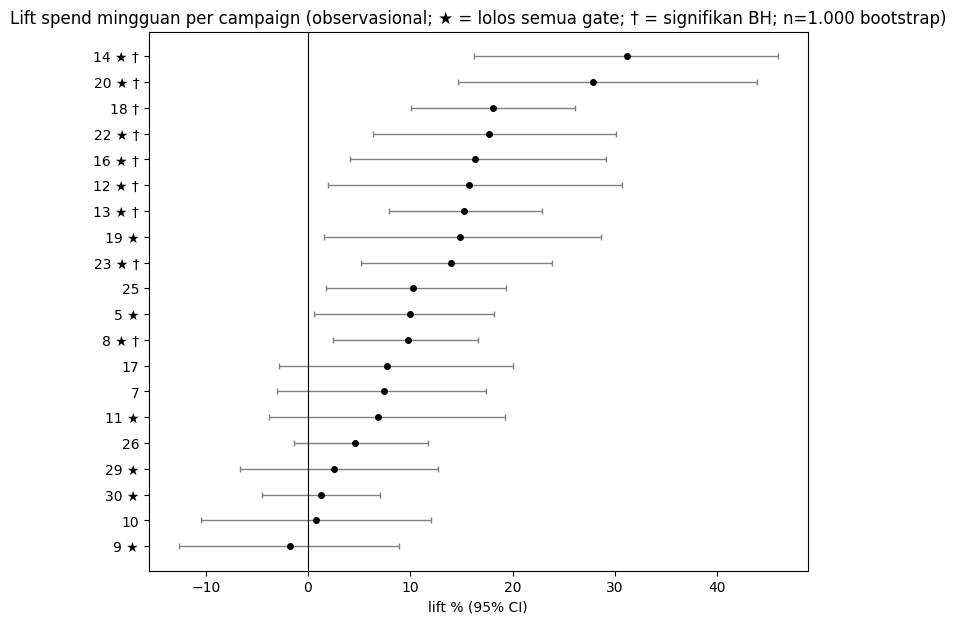

pooled k=14: FE $3.83 [2.89, 4.77] | RE $4.87 [3.06, 6.68] | I² = 66%


In [5]:
pe = pooled_effect(results)
plot = est.sort_values("lift_pct")
star = plot["reliability_flag"].str.startswith("layak")
sig = plot["significance"].str.startswith("signifikan")
fig, ax = plt.subplots(figsize=(8.5, 7))
y = np.arange(len(plot))
ax.errorbar(plot["lift_pct"], y, xerr=[plot["lift_pct"] - plot["lift_ci_low"], plot["lift_ci_high"] - plot["lift_pct"]],
            fmt="o", ms=4, color="black", ecolor="gray", elinewidth=1, capsize=2)
ax.set_yticks(y)
ax.set_yticklabels([f"{int(c)}{' ★' if s else ''}{' †' if g else ''}" for c, s, g in zip(plot["campaign_id"], star, sig)])
ax.axvline(0, color="black", lw=0.8)
ax.set(title="Lift spend mingguan per campaign (observasional; ★ = lolos semua gate; † = signifikan BH; n=1.000 bootstrap)",
       xlabel="lift % (95% CI)")
plt.show()
print(f"pooled k={pe['k']}: FE ${pe['att_fe']:.2f} [{pe['att_fe_ci_low']:.2f}, {pe['att_fe_ci_high']:.2f}] | "
      f"RE ${pe['att_re']:.2f} [{pe['att_re_ci_low']:.2f}, {pe['att_re_ci_high']:.2f}] | I² = {pe['i_squared']:.0%}")

## 5. Ekonomi voucher — dua batas, bukan satu angka

Biaya voucher dihitung dua cara: **atribusi ketat** (nilai kupon pada produk dalam daftar kupon campaign itu) dan **batas konservatif** (seluruh kupon yang diredeemasi treated selama window — untuk campaign menengah didominasi kupon campaign lain, 93–99% dari total).

Setelah pengondisian win-back menurunkan estimasi efek, ekonominya kembali moderat: backbone yang bersih (8 dan 13) menghasilkan **$3,3–$3,6 incremental spend per $1 voucher** dengan atribusi ketat — break-even di margin 28–30%, jadi baru menguntungkan pada margin ≥ 35%; batas konservatif tetap negatif. Kesimpulan bisnis yang jujur: campaign ini **mendekati** impas, tidak melampauinya.

In [6]:
eco_cols = ["campaign_id", "reliability_flag", "inc_spend_per_dollar", "margin25_per_dollar", "margin35_per_dollar",
            "inc_spend_per_dollar_allcoupons", "margin35_per_dollar_allcoupons"]
eco = est[est["campaign_id"].isin((8, 13, 18))][eco_cols].copy()
eco["break_even_margin"] = 1 / eco["inc_spend_per_dollar"]
eco["reliability_flag"] = eco["reliability_flag"].str.replace(" (observasional)", "", regex=False)
display(eco.round(3))
print("break-even margin = 1 / (incremental spend per $1, atribusi ketat)")

,campaign_id,reliability_flag,inc_spend_per_dollar,margin25_per_dollar,margin35_per_dollar,inc_spend_per_dollar_allcoupons,margin35_per_dollar_allcoupons,break_even_margin
7,8,layak — utama,3.549,-0.113,0.242,1.010,-0.647,0.282
12,13,layak — utama,3.309,-0.173,0.158,1.382,-0.516,0.302
17,18,tidak reliable — pre-trend jauh,2.522,-0.369,-0.117,1.336,-0.532,0.396


break-even margin = 1 / (incremental spend per $1, atribusi ketat)


## 6. Artefak & angka kunci

In [7]:
display(pd.DataFrame(
    [(a, f"{(PROCESSED_DIR / a).stat().st_size / 1e6:.1f} MB") for a in ("campaign_did_results.parquet", "campaign_event_study.parquet")],
    columns=["artefak (data/processed/)", "ukuran"],
))
layak = results[results["reliability_flag"].str.startswith("layak")]
print(f"lolos semua gate: {len(layak)} campaign {sorted(layak['campaign_id'].tolist())}")
print(f"flagged pre-trend jauh: {sorted(est.loc[~est['far_pre_trend_ok'], 'campaign_id'].tolist())}")
print(results["reliability_flag"].value_counts().to_string())

,artefak (data/processed/),ukuran
0,campaign_did_results.parquet,0.0 MB
1,campaign_event_study.parquet,0.0 MB


lolos semua gate: 14 campaign [5, 8, 9, 11, 12, 13, 14, 16, 19, 20, 22, 23, 29, 30]
flagged pre-trend jauh: [7, 10, 17, 18, 25, 26]
reliability_flag
layak (observasional)              12
tidak reliable                      9
tidak reliable — pre-trend jauh     6
layak — utama (observasional)       2
excluded                            1


## Catatan kualitas & batasan

- **Semua estimasi observasional** — valid di bawah asumsi unconfoundedness; dua placebo, balance, dan overlap mengurangi risikonya, bukan menghapus.
- **Seleksi win-back terkondisikan, bukan tereliminasi**: estimasi turun ~30% setelah trajektori dan dip dikontrol; sisa bias mean-reversion yang tak teramati tidak bisa dikecualikan. Campaign 18 gagal placebo jauh dan ditandai meski signifikan BH — signifikansi statistik bukan substitusi identifikasi.
- Estimasi **spesifikasi-sensitif** (rentang IPW vs overlap ±10–20%; pengondisian win-back −30%): angka dibaca sebagai rentang, bukan titik.
- Efek rata-rata (meta-analysis) punya heterogenitas besar (I² 66%); random-effects $4,87 lebih relevan daripada fixed-effect bila campaign dianggap sampel dari populasi campaign.
- Biaya voucher dua tingkat: atribusi ketat masih proxy (keanggotaan daftar produk, bukan identitas kupon); batas konservatif menghitung kupon campaign lain yang kebetulan sejalan.
- CI bootstrap memegang bobot propensity tetap; diagnostik refit-propensity menghasilkan CI praktis identik — bobot overlap terbatas membuat ketidakpastian propensity kecil.
- Signifikansi memakai koreksi multiplicity BH (q < 0,05) atas 20 pengujian; tanpa koreksi, tiga campaign tambahan akan terlihat "signifikan".
- Semua nominal USD historis; bukan klaim kausal; margin tetap parameter (15/25/35%), bukan data.